# Subred a Trabajar 


## 1. Datos

El notebook se arma solo: define la subred y carga septiembre desde `data/raw/` (primero hay que correr `data_cleaning.ipynb` para que los CSV estén descargados).

Por ahora lee los datos **crudos**. Cuando `data_cleaning.ipynb` guarde los datos limpios, esta celda se cambia para leer ese archivo.

Columnas que usa el mapa:
- `fecha`, `hora_retiro`: día y hora del retiro.
- `es_habil`: lunes a viernes, sin el festivo del 16 de septiembre ni los días irregulares del 14 y 15 (cierre de la zona Buenavista).
- `retiro_subred`, `arribo_subred`: si el retiro o el arribo es una de las 5 estaciones.

In [5]:
from pathlib import Path
import json
import os, certifi
os.environ["SSL_CERT_FILE"] = certifi.where()
os.environ["REQUESTS_CA_BUNDLE"] = certifi.where()

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import contextily as ctx
from matplotlib.patches import FancyArrowPatch
from matplotlib.lines import Line2D

RUTA_LIMPIO = Path("data/clean/trips_2026-09.parquet")
RUTA_ESTACIONES = Path("data/raw/station_information.json")
DIR_FIG = Path("outputs/figuras")

SUBRED = {
    "014": "Reforma",
    "027": "Reforma",
    "018": "Reforma",
    "271-272": "Buenavista",
    "273-274": "Buenavista",
}
COLORES = {"Buenavista": "#d1495b", "Reforma": "#2e86ab"}

df = pd.read_parquet(RUTA_LIMPIO)   

n_dias = df.loc[df.es_habil, "fecha"].nunique()
print(f"Viajes limpios en septiembre: {len(df):,}")
print(f"Días hábiles: {n_dias}")

Viajes limpios en septiembre: 1,495,520
Días hábiles: 19


## 2. Mapa de la red

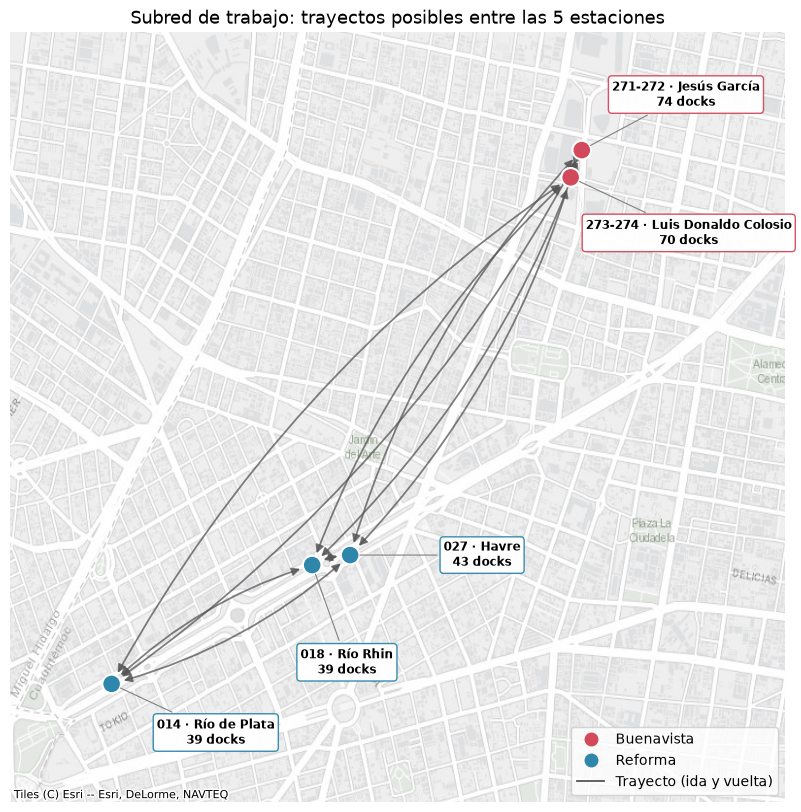

In [6]:
from itertools import combinations

# --- Estaciones en Web Mercator, con nombre corto y docks
info = pd.DataFrame(json.loads(RUTA_ESTACIONES.read_text())["data"]["stations"])
est = info[info.short_name.isin(SUBRED)].set_index("short_name")
R = 6378137
est["x"] = R * np.radians(est.lon)
est["y"] = R * np.log(np.tan(np.pi / 4 + np.radians(est.lat) / 2))
est["grupo"] = est.index.map(SUBRED)
est["calle"] = (est["name"].str.replace(r"^CE-[\d-]+\s*(Reforma\s*-\s*)?", "", regex=True)
                            .str.split(" - ").str[0])       # "CE-014 Reforma - Río de Plata" -> "Río de Plata"

# Posición de cada etiqueta respecto a su estación (en puntos), para que no se encimen
OFFSET = {"271-272": (75, 40), "273-274": (85, -40), "027": (95, 0), "018": (25, -70), "014": (75, -35)}

fig, ax = plt.subplots(figsize=(10, 10))

# --- Red completa: un trayecto por cada par de estaciones, en ambos sentidos
for k, (a, b) in enumerate(combinations(est.index, 2)):
    o, d = est.loc[a], est.loc[b]
    ax.add_patch(FancyArrowPatch(
        (o.x, o.y), (d.x, d.y), connectionstyle=f"arc3,rad={0.12 if k % 2 else -0.12}",
        arrowstyle="<|-|>", mutation_scale=12, shrinkA=9, shrinkB=9,
        lw=1.3, color="#555555", alpha=0.75, zorder=2))

ax.scatter(est.x, est.y, s=180, c=est.grupo.map(COLORES), edgecolor="white", lw=1.5, zorder=3)
for code, r in est.iterrows():
    ax.annotate(f"{code} · {r.calle}\n{int(r.capacity)} docks", (r.x, r.y),
                xytext=OFFSET.get(code, (10, 10)), textcoords="offset points",
                ha="center", va="center", fontsize=8.5, weight="bold", zorder=5,
                bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=COLORES[r.grupo], alpha=0.95),
                arrowprops=dict(arrowstyle="-", color="gray", lw=0.8, shrinkB=7))

pad = 500
ax.set_xlim(est.x.min() - pad, est.x.max() + 2 * pad)   # más espacio a la derecha para las etiquetas de Buenavista
ax.set_ylim(est.y.min() - pad, est.y.max() + pad)
ctx.add_basemap(ax, crs="EPSG:3857", source=ctx.providers.Esri.WorldGrayCanvas)
ax.set_axis_off()
ax.set_title("Subred de trabajo: trayectos posibles entre las 5 estaciones", fontsize=13)
ax.legend(handles=[Line2D([], [], marker="o", ls="", color=c, label=g, markersize=9)
                   for g, c in COLORES.items()]
                  + [Line2D([], [], color="#555555", lw=1.3, label="Trayecto (ida y vuelta)")],
          loc="lower right")

DIR_FIG.mkdir(parents=True, exist_ok=True)
plt.savefig(DIR_FIG / "red_subred.png", dpi=200, bbox_inches="tight")
plt.show()